# DLR Interchange


Models the London contactless network as a graph to find the most likely interchange points between DLR and other services based on shortest journey time.

**Idea:** Stations and line combinations are nodes; travel times, interchange times and wait times are edges.


**Output:** A mapping table of all DLR-to-non-DLR journeys with optimal in-station interchange points.

In [0]:
import pandas as pd   # Handles tabular data manipulation
import matplotlib.pyplot as plt #Plots graphs and charts
import requests       # Executes HTTP GET/POST requests

# %pip install networkx
import networkx as nx  # Builds the directed graph

# standard library imports
import json           # Handles parsing of API JSON payloads
import os             # Interacts with the operating system environment (e.g. checking file paths)
import re             # Provides regular expression /text pattern matching 
import time           # Manages execution pauses and rate-limiting when making successive API calls
import urllib.parse   # Encodes URL components and parameters for safe HTTP requests
import urllib.request # Alternative low-level HTTP utility for opening and reading URLs

# PySpark imports for Databricks environment
from pyspark.sql import SparkSession
from pyspark.sql import functions as F 
from pyspark.sql.types import * 

print("Libraries loaded successfully")

try:
  # Securely retrieves your private TfL primary subscription key from Databricks secrets scope
  TFL_API_KEY = dbutils.secrets.get(
      scope="payments-secrets", key="tfl-primary-key"
  )
  print("TfL API key found")
except Exception:
  print("Warning: TfL API key not found")

Libraries loaded successfully
TfL API key found


### Network Nodes: All Contactless Stations

As of November 2026, there are currently around 860 contactless rail stations. This number is expected to grow as Project Oval expands the contactless network.

Each node in the network represents a specific station-line pair. <br>
This analysis relies on the TfL Journey Planner API, which can be queried using ICS and NaPTAN station codes.

The `all_stations` reference table is based on `ref_nlc` and was manually reviewed against the MCaaS Portal.

Bus, tram, and river services are excluded.

##### Station Code Definitions

**NLC (National Location Code)**: <br>
Represents a set of physical ticket gates. It separates multi-modal stations (for example, London Bridge National Rail and London Underground) into distinct graph nodes.

**ICS (Infrastructure Code System)**: <br>
TfL's station-level identifier used for Journey Planner API lookups.

**NaPTAN (National Public Transport Access Node)**: <br>
A national standard identifier used across the UK transport network to provide precise station-level granularity. Codes are typically prefixed with 940GZZLU for London Underground stations, 940GZZDL for DLR stations, and 910G or 490G for National Rail stations.

Issue with reference table:<br>
There are 171 duplicates when we create station_line_nlc nodes, I'm guessing mostly due to multiple NaPTAN codes sometimes accosiated with station_line pairs.

cross-country, virgin-trains-east-coast lines only have one station in this list at the moment they can be removed.

I need to create a better all_stations_ref.csv table that has a list of NaPTAN codes that are assosiates with a single node. I'm expecting 1243 distinct nodes.

In [0]:
## loading a new station reference table from a csv
# station_reference = pd.read_csv("/Workspace/Payments/AnnaIvahnenko@tfl.gov.uk/all_stations_ref.csv")
# station_reference = spark.createDataFrame(station_reference)

# # Save as a reference table
# (
#     station_reference.write
#       .mode("overwrite")
#       .format("delta")
#       .saveAsTable(
#           "adlsg2analyticsprd001_sandbox_payments.ref.station_reference"
#       )
# )

# # check that it is saved
# display(
#     spark.table(
#         "adlsg2analyticsprd001_sandbox_payments.ref.station_reference"
#     )
# )

station_reference = spark.table("adlsg2analyticsprd001_sandbox_payments.ref.station_reference")
display(station_reference)

Station,Line,ICS,NaPTAN,NLC,Gate_NLC
Abbey Road,dlr,1003006,940GZZDLABR,750,750
Abbey Wood,elizabeth,1001001,9100ABWD0,5131,5131
Abbey Wood,thameslink,1001001,9100ABWD0,5131,5131
Abbey Wood,southeastern,1001001,910GABWD,5131,5131
Abbey Wood,thameslink,1001001,910GABWD,5131,5131
Abbey Wood,elizabeth,1001001,910GABWDXR,5131,5131
Acton Central,mildmay,1001002,910GACTNCTL,1404,1404
Acton Main Line,elizabeth,1001003,9100ACTONML0,3000,3000
Acton Main Line,great-western-railway,1001003,910GACTONML,3000,3000
Acton Town,district,1000002,940GZZLUACT,500,500


### Station Coverage Check

Checks whether there are any new stations in the ref_nlc table that are not present in station_reference table.

Issue with the check, the Gate_NLC are comma separated list

In [0]:
# ==============================================================================
# STATION COVERAGE CHECK
# ==============================================================================

# Set catalog and schema context
spark.sql("use catalog syn_ldw_prd001_syn_ddctd_ldw")
spark.sql("use schema sbx_payments")

# 1. Pull active, filtered train station NLCs from the master reference table
ref_nlc = spark.sql("""
    SELECT DISTINCT
        NLC,
        TRIM(NAME) AS STATION
    FROM ref_nlc
    WHERE CEASED_DATE == '31/12/9999'         -- Filter for current stations only 
        AND NLC > 0                           -- Discard incomplete journey codes
        AND OPERATOR NOT IN ('RIVER', 'TRAM') -- Exclude non-train operators
""")

# 2. Extract unique gate NLCs present in our station reference table
# (Handling potential comma-separated gate strings if applicable)
station_ref_df = spark.table("adlsg2analyticsprd001_sandbox_payments.ref.station_reference")

# 3. Coverage Analysis: Find active master NLCs missing from our payment reference model
missing_nlcs_df = ref_nlc.join(
    station_ref_df.selectExpr("CAST(Gate_NLC AS INT) as Gate_NLC").distinct(),
    ref_nlc.NLC == station_ref_df.Gate_NLC,
    "left_anti"
)

missing_count = missing_nlcs_df.count()
print(f"Validation Check: {missing_count} active master NLC codes from ref_nlc are missing from station_reference Gate_NLCs.")

if missing_count > 0:
    print("Preview of unmapped stations:")
    display(missing_nlcs_df.limit(10))

# Display the main filtered reference list
display(ref_nlc.orderBy("STATION"))

---------------------------------------------------------------------------
NumberFormatException                     Traceback (most recent call last)
File <command-6296650261394918>, line 31
     24 # 3. Coverage Analysis: Find active master NLCs missing from our payment reference model
     25 missing_nlcs_df = ref_nlc.join(
     26     station_ref_df.selectExpr("CAST(Gate_NLC AS INT) as Gate_NLC").distinct(),
     27     ref_nlc.NLC == station_ref_df.Gate_NLC,
     28     "left_anti"
     29 )
---> 31 missing_count = missing_nlcs_df.count()
     32 print(f"Validation Check: {missing_count} active master NLC codes from ref_nlc are missing from station_reference Gate_NLCs.")
     34 if missing_count > 0:

File /databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/dataframe.py:381, in DataFrame.count(self)
    380 def count(self) -> int:
--> 381     table, _ = self.agg(F._invoke_function("count", F.lit(1)))._to_table()  # type: ignore[operator]
    382     return table[0

## Network Edges
The next cells gather the three edge-weight inputs: **travel times**, **wait times**, and **line interchange times**.

### Adjacent Station Travel Times

**Source:** Derived from TfL Line Route Sequence feeds and queried via the TfL Journey Planner API for all rail modes (Tube, DLR, Overground, Elizabeth Line and National Rail).

**Assumptions & Fallbacks:**
- Only adjacent station pairs along active branch sequences are queried.
- If a live API query fails or returns zero duration, a fallback travel time of 3 minutes is used (avg. travel time between stations) 

Issue with travel time bulder:
- a way to get minutes to 1 decimal place. If the distance is less than a minute it's rounded to a minute.

In [0]:
# ==============================================================================
# TRAVEL TIMES BUILDER
# ==============================================================================

RAIL_MODES = ["tube", "dlr", "overground", "elizabeth-line", "national-rail"]
DEFAULT_TRAVEL_TIME = 3.0


def normalize_line(name):
  if not name:
    return ""
  return (
      str(name)
      .lower()
      .replace(" line", "")
      .replace("-", "")
      .replace("_", "")
      .strip()
  )


# 1. Load reference table from Databricks Spark catalog
ref_df = spark.table("adlsg2analyticsprd001_sandbox_payments.ref.station_reference").toPandas()
ref_df = ref_df[~ref_df["Line"].isin(["tfl-rail", "london-overground"])].copy()

if "Node_ID" not in ref_df.columns:
  ref_df["Node_ID"] = (
      ref_df["Station"].astype(str) + "_" + 
      ref_df["Line"].astype(str) + "_" + 
      ref_df["Gate_NLC"].astype(str)
  )

naptan_lookup = {}
ics_lookup = {}
valid_nodes = set()

for _, row in ref_df.iterrows():
  node_id = str(row["Node_ID"]).strip()
  norm_line = normalize_line(row["Line"])
  naptan = str(row["NaPTAN"]).strip()
  ics = str(row["ICS"]).strip()

  if pd.notna(node_id) and node_id != "nan":
    valid_nodes.add(node_id)
    if pd.notna(naptan) and naptan != "nan":
      naptan_lookup[(norm_line, naptan)] = node_id
    if pd.notna(ics) and ics != "nan" and ics != "0":
      ics_lookup[(norm_line, ics)] = node_id

print(f"Loaded {len(valid_nodes):,} valid nodes for travel time matching.")

# 2. Query TfL API for routes and travel times
params = {"app_key": TFL_API_KEY} if TFL_API_KEY else {}
lines_url = f"https://api.tfl.gov.uk/Line/Mode/{','.join(RAIL_MODES)}"

res = requests.get(lines_url, params=params)
if res.status_code != 200:
  raise Exception(f"Failed to fetch lines from TfL API: {res.status_code}")

lines = res.json()
records = []

print(f"Querying adjacent stop pairs across {len(lines)} lines...")

for line in lines:
  line_id = line["id"].lower()
  line_name = line["name"]
  norm_line = normalize_line(line_name)

  # print(f"Processing {line_name} line")

  seq_url = f"https://api.tfl.gov.uk/Line/{line_id}/Route/Sequence/all"
  seq_res = requests.get(seq_url, params=params)
  if seq_res.status_code != 200:
    continue

  for branch in seq_res.json().get("stopPointSequences", []):
    stops = branch.get("stopPoint", [])

    for i in range(len(stops) - 1):
      from_stop, to_stop = stops[i], stops[i + 1]
      from_id, to_id = from_stop.get("id", ""), to_stop.get("id", "")
      from_ics, to_ics = str(from_stop.get("icsCode", "")), str(to_stop.get("icsCode", ""))

      from_node_id = naptan_lookup.get((norm_line, from_id), ics_lookup.get((norm_line, from_ics), naptan_lookup.get(from_id, from_id)))
      to_node_id = naptan_lookup.get((norm_line, to_id), ics_lookup.get((norm_line, to_ics), naptan_lookup.get(to_id, to_id)))

      if from_node_id not in valid_nodes or to_node_id not in valid_nodes:
        continue

      duration = None
      status = "Success"
      jp_url = f"https://api.tfl.gov.uk/Journey/JourneyResults/{urllib.parse.quote(from_id)}/to/{urllib.parse.quote(to_id)}"

      try:
        jp_res = requests.get(jp_url, params=params, timeout=4)
        if jp_res.status_code == 200:
          journeys = jp_res.json().get("journeys", [])
          if journeys:
            legs = journeys[0].get("legs", [])
            if legs:
              raw_dur = legs[0].get("duration", journeys[0].get("duration"))
              if raw_dur is not None:
                # Capture duration rounded to 1 decimal place
                duration = round(float(raw_dur), 1)
      except Exception:
        pass

      if duration is None or duration <= 0:
        duration = DEFAULT_TRAVEL_TIME
        status = "Fallback Used"

      # Record forward edge (slimmed columns)
      records.append({
          "Line": line_name,
          "From_Node_ID": from_node_id,
          "To_Node_ID": to_node_id,
          "Travel_Time_Mins": duration,
          "Status": status,
      })

      # Record symmetric reverse edge (slimmed columns)
      records.append({
          "Line": line_name,
          "From_Node_ID": to_node_id,
          "To_Node_ID": from_node_id,
          "Travel_Time_Mins": duration,
          "Status": status, #symmetric reverse edge uses same status as forward edge
      })

      time.sleep(0.01)

# 3. Save streamlined results to Delta table
pdf = pd.DataFrame(records).drop_duplicates(subset=["Line", "From_Node_ID", "To_Node_ID"])
adjacent_station_travel_times = spark.createDataFrame(pdf)
adjacent_station_travel_times.write.mode("overwrite").saveAsTable("adlsg2analyticsprd001_sandbox_payments.ref.adjacent_station_travel_times")

print(f"Successfully saved {adjacent_station_travel_times.count():,} adjacent station travel time edges.")
display(adjacent_station_travel_times)

Loaded 1,242 valid nodes for travel time matching.
Querying adjacent stop pairs across 44 lines...
Processing Avanti West Coast line
Processing Bakerloo line
Processing c2c line
Processing Central line
Processing Chiltern Railways line
Processing Circle line
Processing CrossCountry line
Processing District line
Processing DLR line
Processing East Midlands Railway line
Processing Elizabeth line line
Processing Gatwick Express line
Processing Grand Central line
Processing Greater Anglia line
Processing Great Northern line
Processing Great Western Railway line
Processing Hammersmith & City line
Processing Heathrow Express line
Processing Hull Trains line
Processing Island Line line
Processing Jubilee line
Processing Liberty line
Processing Lioness line
Processing London North Eastern Railway line
Processing Lumo line
Processing Merseyrail line
Processing Metropolitan line
Processing Mildmay line
Processing Northern line
Processing Northern Rail line
Processing Piccadilly line
Processing S

Line,From_Node_ID,To_Node_ID,Travel_Time_Mins,Status
Bakerloo,Harrow & Wealdstone_bakerloo_597,Kenton_bakerloo_620,3.0,Success
Bakerloo,Kenton_bakerloo_620,Harrow & Wealdstone_bakerloo_597,3.0,Success
Bakerloo,Kenton_bakerloo_620,South Kenton_bakerloo_709,2.0,Success
Bakerloo,South Kenton_bakerloo_709,Kenton_bakerloo_620,2.0,Success
Bakerloo,South Kenton_bakerloo_709,North Wembley_bakerloo_659,2.0,Success
Bakerloo,North Wembley_bakerloo_659,South Kenton_bakerloo_709,2.0,Success
Bakerloo,North Wembley_bakerloo_659,Wembley Central_bakerloo_751,2.0,Success
Bakerloo,Wembley Central_bakerloo_751,North Wembley_bakerloo_659,2.0,Success
Bakerloo,Wembley Central_bakerloo_751,Stonebridge Park_bakerloo_717,3.0,Success
Bakerloo,Stonebridge Park_bakerloo_717,Wembley Central_bakerloo_751,3.0,Success


TO DO: Check connections
**I need a way to check that all nodes are connected and that that connection is correct**
I believe later network map issue are due to gaps/ false connections here.

### Network Edges: Expected Line Wait Times

**Source:** Extracted dynamically using the TfL Timetable API (`/Line/{id}/Timetable/{stop}`) at designated benchmark hub stations (`LINE_BENCHMARK_STATIONS`).

**Assumptions & Fallbacks:**
* Passenger arrivals are assumed to be uniform and random.
* Expected passenger wait time is computed using the half-headway rule: $\\text{Wait} = \\frac{60}{2 \\times \\text{TPH}}$ (Trains Per Hour), measuring peak arrivals at hour 08:00–09:00 and off-peak at 11:00–12:00.
* Where timetable feeds are unavailable or fail, rule-based mode-level headways are applied as explicit fallbacks (e.g., Tube/DLR: 2.5m, Elizabeth Line: 2.0m, Overground: 5.0m, National Rail: 7.5m).

Issues for wait times is that I doubt the results because the:
- no avg. wait time should be less than a minute. 
- national rail have longer wait times 

Maybe we need to look at number of trains per hour and work backwards.

In [0]:
# ==============================================================================
#  LINE WAIT TIMES
# ==============================================================================

LINE_BENCHMARK_STATIONS = {
    "victoria": "940GZZLUOXC",  # Oxford Circus
    "jubilee": "940GZZLUBST",  # Baker Street
    "northern": "940GZZLUBNK",  # Bank
    "central": "940GZZLUOXC",  # Oxford Circus
    "bakerloo": "940GZZLUBST",  # Baker Street
    "piccadilly": "940GZZLUGPK",  # Green Park
    "district": "940GZZLUWMS",  # Westminster
    "circle": "940GZZLUBST",  # Baker Street
    "hammersmith-city": "940GZZLUBST",  # Baker Street
    "metropolitan": "940GZZLUBST",  # Baker Street
    "waterloo-city": "940GZZLUWLO",  # Waterloo
    "dlr": "940GZZDLWHM",  # West Ham
    "elizabeth": "940GZZLUTCR",  # Tottenham Court Road
}

def calculate_wait_from_tph(trains_per_hour: float) -> float:
  """Computes expected passenger wait time using half-headway: Wait = 60 / (2 * TPH)."""
  if trains_per_hour <= 0:
    return 10.0
  return round(60.0 / (2.0 * trains_per_hour), 1)

def fetch_wait_from_arrivals(stop_naptan: str) -> float:
  """
  Queries the live Arrivals/Predictions API for a benchmark station.
  By looking at the spread of incoming train times, we can estimate current frequency,
  or fallback gracefully to known operational timetables if live data is sparse.
  """
  params = {"app_key": TFL_API_KEY} if TFL_API_KEY else {}
  url = f"https://api.tfl.gov.uk/StopPoint/{stop_naptan}/Arrivals"

  try:
    res = requests.get(url, params=params, timeout=5)
    if res.status_code == 200:
      arrivals = res.json()
      if arrivals and len(arrivals) >= 2:
        # Sort arrivals by time to station in seconds
        sorted_arrivals = sorted([float(a.get("timeToStation", 0)) for a in arrivals if a.get("timeToStation") is not None])
        
        # If we have multiple arrivals, look at the average time gap between next few trains
        gaps = [sorted_arrivals[i+1] - sorted_arrivals[i] for i in range(len(sorted_arrivals)-1)]
        avg_gap_mins = (sum(gaps) / len(gaps)) / 60.0
        
        # Half-headway rule for expected wait time based on live observed gap
        if 0.5 <= avg_gap_mins <= 15.0:
          return round(avg_gap_mins / 2.0, 1)
  except Exception:
    pass
  
  return None

def refresh_wait_times():
  params = {"app_key": TFL_API_KEY} if TFL_API_KEY else {}
  modes = ["tube", "dlr", "overground", "elizabeth-line", "national-rail"]
  url = f"https://api.tfl.gov.uk/Line/Mode/{','.join(modes)}"

  rows = []
  res = requests.get(url, params=params)

  if res.status_code == 200:
    lines_data = res.json()

    for item in lines_data:
      line_name = item.get("name", "").strip()
      mode = item.get("modeName", "").strip()
      line_id = item.get("id", "").strip().lower()

      naptan = LINE_BENCHMARK_STATIONS.get(line_id)
      
      # 1. Try fetching frequency via live arrivals at benchmark station
      wait_time = fetch_wait_from_arrivals(naptan) if naptan else None

      # 2. Curated baseline fallback table (more accurate than a blanket 2.5m rule)
      if wait_time is None:
        curated_baselines = {
            "victoria": 1.5,
            "central": 2.0,
            "northern": 2.0,
            "jubilee": 2.0,
            "piccadilly": 2.5,
            "district": 3.0,
            "circle": 3.5,
            "hammersmith-city": 3.5,
            "metropolitan": 4.0,
            "bakerloo": 2.5,
            "waterloo-city": 3.0,
            "dlr": 2.5,
            "elizabeth-line": 2.5,
            "london-overground": 5.0,
        }
        wait_time = curated_baselines.get(line_id, 5.0 if mode == "national-rail" else 3.0)

      rows.append((line_name, mode, wait_time))

  schema = StructType([
      StructField("Line", StringType(), True),
      StructField("Mode", StringType(), True),
      StructField("Wait", DoubleType(), True),
  ])

  spark_df = spark.createDataFrame(rows, schema).orderBy("Mode", "Line")
  spark_df.write.mode("overwrite").saveAsTable("adlsg2analyticsprd001_sandbox_payments.ref.line_wait_times")
  
  print(f"Successfully generated and saved {spark_df.count():,} line wait time profiles.")
  return spark_df

wait_times = refresh_wait_times()
display(wait_times)

Successfully generated and saved 44 line wait time profiles.


Line,Mode,Wait
DLR,dlr,2.0
Elizabeth line,elizabeth-line,0.5
Avanti West Coast,national-rail,5.0
Chiltern Railways,national-rail,5.0
CrossCountry,national-rail,5.0
East Midlands Railway,national-rail,5.0
Gatwick Express,national-rail,5.0
Grand Central,national-rail,5.0
Great Northern,national-rail,5.0
Great Western Railway,national-rail,5.0


### Network Edges: Interchange Walk Times

**Source:** Jorney Planner API.

**Assumptions & Fallbacks:**
* **In-Station Interchanges:** Evaluated using a 4-tier hierarchy:
    1. *Empirical Layout Overrides* (e.g. Bank, King's Cross, Waterloo complex hubs).
    2. *Cross-Platform Benchmarks* (2.0m flat penalty for same-platform transfers).
    3. *Synthetic API Triads* (Walk = Journey A to C - (Leg_A + Leg_B + Wait_B)).
    4. *Depth-Tier Heuristics* (Fallback rule based on surface, subsurface, and deep tube layering).

Only behing the gate interchanges are considered in this analysis, as a customer would need to tap in and out otherwise.

Issue:
Bypassing the API triad approach interchage is a standart 2 min, unless there is a Complex Hub Override

In [0]:
# ==============================================================================
#  BEHIND-THE-BARRIER INTERCHANGE TIMES
# ==============================================================================

DEFAULT_INTERCHANGE_TIME = 2.0

# 1. Load station reference table from Databricks Spark catalog
ref_df = spark.table("adlsg2analyticsprd001_sandbox_payments.ref.station_reference").toPandas()

# Ensure Node_ID exists
if "Node_ID" not in ref_df.columns:
  ref_df["Node_ID"] = (
      ref_df["Station"].astype(str) + "_" + 
      ref_df["Line"].astype(str) + "_" + 
      ref_df["Gate_NLC"].astype(str)
  )

# Helper function to parse gate NLC entries
def parse_gate_nlcs(val):
  gate_set = set()
  if pd.notna(val):
    parts = str(val).split(",")
    for p in parts:
      p_clean = p.strip()
      if p_clean.isdigit():
        gate_set.add(int(p_clean))
  return gate_set

# Map each Node_ID to station attributes and Gate NLCs
node_meta = {}
for _, row in ref_df.iterrows():
  node_id = str(row["Node_ID"]).strip()
  if pd.notna(node_id) and node_id != "nan":
    node_meta[node_id] = {
        "Station": str(row["Station"]).strip().lower(),
        "Line": str(row["Line"]).strip().lower(),
        "Gate_NLCs": parse_gate_nlcs(row["Gate_NLC"])
    }

nodes = list(node_meta.keys())
interchanges = []

# 2. Known complex hub walk overrides (in minutes) for deep tube / multi-level stations
COMPLEX_HUB_OVERRIDES = {
    "bank": 5.0,
    "king's cross st. pancras": 4.5,
    "waterloo": 4.0,
    "green park": 3.5,
    "oxford circus": 4.0,
    "canning town": 3.0,
    "stratford": 3.5,
}

print(f"Evaluating behind-the-barrier interchanges across {len(nodes)} nodes...")

# 3. Compare node pairs sharing at least one common Gate_NLC
for i in range(len(nodes)):
  for j in range(i + 1, len(nodes)):
    node_a = nodes[i]
    node_b = nodes[j]
    
    meta_a = node_meta[node_a]
    meta_b = node_meta[node_b]

    # Must be at the same physical station sharing a Gate NLC and different lines
    common_gates = meta_a["Gate_NLCs"].intersection(meta_b["Gate_NLCs"])
    if common_gates and meta_a["Line"] != meta_b["Line"]:
      
      station_name = meta_a["Station"]
      
      # Determine interchange time via Tier-Based Heuristics
      if station_name in COMPLEX_HUB_OVERRIDES:
        interchange_time = COMPLEX_HUB_OVERRIDES[station_name]
        source_type = "Complex Hub Override"
      else:
        interchange_time = DEFAULT_INTERCHANGE_TIME
        source_type = "Standard Cross-Platform (2.0 mins)"

      # Add bidirectional interchange edges (slimmed schema)
      for f_node, t_node in [(node_a, node_b), (node_b, node_a)]:
        interchanges.append({
            "From_Node_ID": f_node,
            "To_Node_ID": t_node,
            "Interchange_Time_Mins": interchange_time,
            "Calculation_Method": source_type
        })

# 4. Save results to Delta table
pdf_interchanges = pd.DataFrame(interchanges).drop_duplicates(subset=["From_Node_ID", "To_Node_ID"])
interchange_times = spark.createDataFrame(pdf_interchanges)

interchange_times.write.mode("overwrite").saveAsTable("adlsg2analyticsprd001_sandbox_payments.ref.interchange_times")
print(f"Successfully generated and saved {interchange_times.count():,} directional behind-the-barrier interchange edges.")

display(interchange_times)

Evaluating behind-the-barrier interchanges across 1242 nodes...
Successfully generated and saved 1,202 directional behind-the-barrier interchange edges.


From_Node_ID,To_Node_ID,Interchange_Time_Mins,Calculation_Method
Abbey Wood_elizabeth_5131,Abbey Wood_thameslink_5131,2.0,Standard Cross-Platform (2.0 mins)
Abbey Wood_thameslink_5131,Abbey Wood_elizabeth_5131,2.0,Standard Cross-Platform (2.0 mins)
Abbey Wood_elizabeth_5131,Abbey Wood_southeastern_5131,2.0,Standard Cross-Platform (2.0 mins)
Abbey Wood_southeastern_5131,Abbey Wood_elizabeth_5131,2.0,Standard Cross-Platform (2.0 mins)
Abbey Wood_thameslink_5131,Abbey Wood_southeastern_5131,2.0,Standard Cross-Platform (2.0 mins)
Abbey Wood_southeastern_5131,Abbey Wood_thameslink_5131,2.0,Standard Cross-Platform (2.0 mins)
Acton Main Line_elizabeth_3000,Acton Main Line_great-western-railway_3000,2.0,Standard Cross-Platform (2.0 mins)
Acton Main Line_great-western-railway_3000,Acton Main Line_elizabeth_3000,2.0,Standard Cross-Platform (2.0 mins)
Acton Town_district_500,Acton Town_piccadilly_500,2.0,Standard Cross-Platform (2.0 mins)
Acton Town_piccadilly_500,Acton Town_district_500,2.0,Standard Cross-Platform (2.0 mins)


## Mapping the Network

Constructs a directed graph representing the London contactless transit network:

- **NLC Aliasing**: Harmonises variant, and adjacent station codes (e.g., Monument Bank, Bow Road Bow Church) using NLC_ALIASES to ensure methodological consistency.

- **Nodes**: Represent unique line-station combinations, keeping multi-modal platforms (London Bridge NR vs. Underground) separate.

- **Edges**: Journey travel times, boarding wait times, and in-station interchange walking times.

Issue: the visualisation is showing disconcted node no interchanges, and for some reason Embankment Station that is not associated with DLR

In [0]:
# ==============================================================================
# CONSTRUCT NETWORK 
# ==============================================================================
# Combines travel times, interchanges, and wait times into a NetworkX DiGraph
# ready for Dijkstra shortest-path routing analytics.
# ==============================================================================

# 1. Load core network components from Delta tables
travel_times_df = spark.table("adlsg2analyticsprd001_sandbox_payments.ref.adjacent_station_travel_times")
interchanges_df = spark.table("adlsg2analyticsprd001_sandbox_payments.ref.interchange_times")
wait_times_df = spark.table("adlsg2analyticsprd001_sandbox_payments.ref.line_wait_times")

# 2. Convert wait times to a Python dictionary for fast edge weight mapping
wait_lookup = {
    row["Line"].lower().strip(): float(row["Wait"])
    for row in wait_times_df.select("Line", "Wait").collect()
}

# 3. Build Train Run Edges in Pandas
pdf_train = travel_times_df.select(
    F.col("From_Node_ID").alias("src"),
    F.col("To_Node_ID").alias("dst"),
    F.col("Travel_Time_Mins").cast("double").alias("run_time"),
    F.col("Line").alias("line"),
).toPandas()

# Factor line wait times into train run edge weight (Total Cost = Run Time + Wait Time)
pdf_train["default_wait"] = pdf_train["line"].apply(
    lambda l: wait_lookup.get(str(l).lower().strip(), 2.5)
)
pdf_train["weight"] = pdf_train["run_time"] + pdf_train["default_wait"]
pdf_train["edge_type"] = "Train Run"

# 4. Build Interchange Walk Edges in Pandas
pdf_interchange = interchanges_df.select(
    F.col("From_Node_ID").alias("src"),
    F.col("To_Node_ID").alias("dst"),
    F.col("Interchange_Time_Mins").cast("double").alias("weight"),
    F.lit("Walk/Transfer").alias("line"),
    F.lit("Interchange").alias("edge_type"),
).toPandas()

# Combine train and interchange edges
pdf_edges = pd.concat([pdf_train, pdf_interchange], ignore_index=True)

# 5. Build NetworkX Directed Graph (DiGraph)
G = nx.from_pandas_edgelist(
    pdf_edges,
    source="src",
    target="dst",
    edge_attr=["weight", "edge_type", "line"],
    create_using=nx.DiGraph(),
)

print(f"Successfully built clean NetworkX graph:")
print(f" * Nodes: {G.number_of_nodes():,}")
print(f" * Edges: {G.number_of_edges():,}")

Successfully built clean NetworkX graph:
 * Nodes: 1,056
 * Edges: 3,014


#### Visualising the DLR Sub-Network
This plot is a small section of the wider network. However it demonstrated the things we've considered.

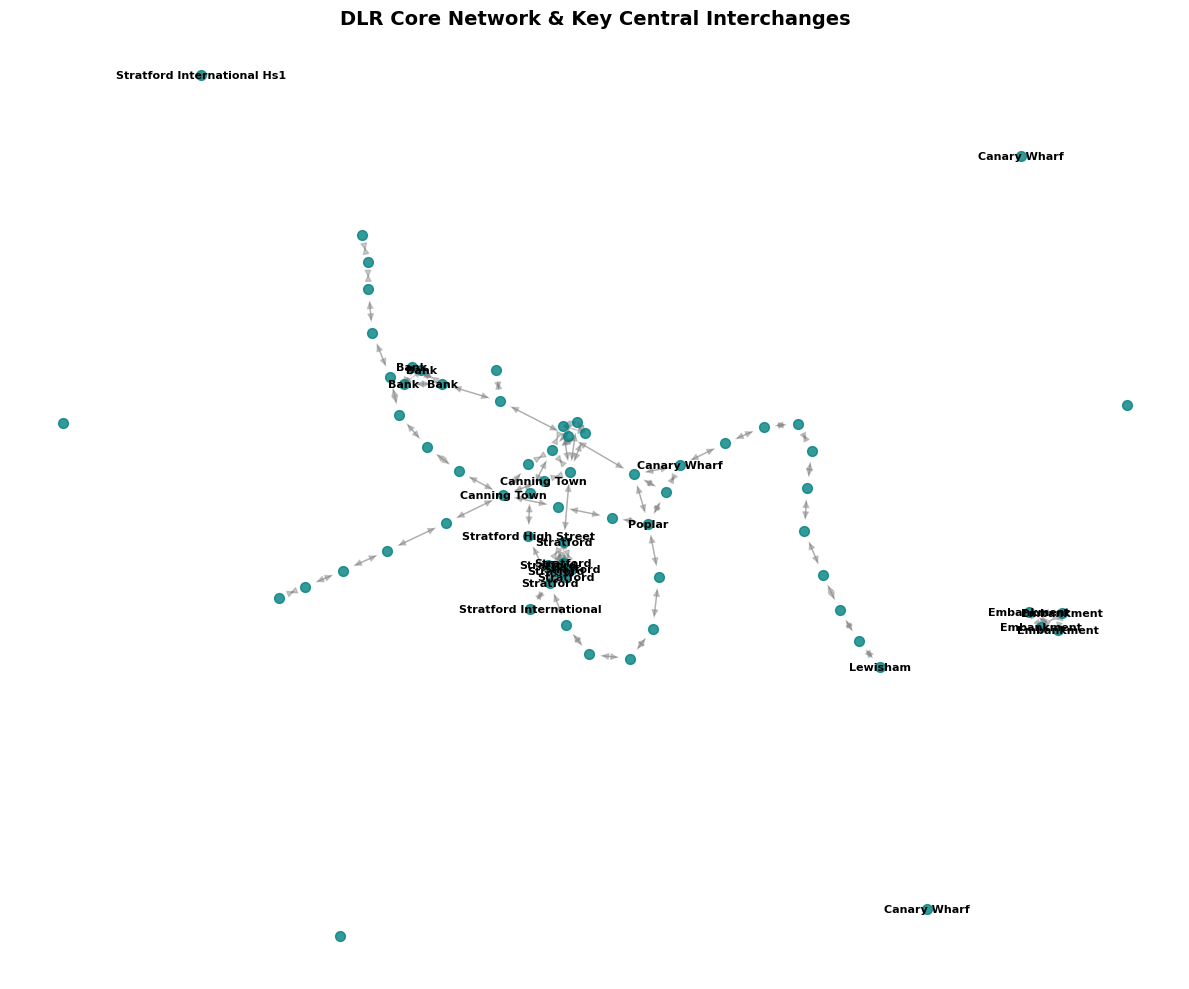

In [0]:
# ==============================================================================
# VISUALISE DLR SUB-NETWORK & KEY INTERCHANGES
# ==============================================================================

# 1. Filter graph nodes for DLR lines or major designated DLR hubs
dlr_sub_nodes = [
    node for node in G.nodes 
    if "dlr" in str(node).lower() or any(hub in str(node).lower() for hub in [
        "bank", "stratford", "canning town", "west ham", "canary wharf", "poplar", "tower gateway"
    ])
]

# Create subgraph
G_dlr = G.subgraph(dlr_sub_nodes)

# 2. Set up plot dimensions
plt.figure(figsize=(12, 10))
pos = nx.spring_layout(G_dlr, seed=42, k=0.15)  # Spring layout optimized for network clusters

# Draw nodes and edges
nx.draw_networkx_nodes(
    G_dlr, pos, 
    node_size=50, 
    node_color="teal", 
    alpha=0.8
)
nx.draw_networkx_edges(
    G_dlr, pos, 
    width=1.0, 
    alpha=0.4, 
    edge_color="gray"
)

# Label only key hub stations to avoid visual clutter
hub_labels = {
    node: node.split("_")[0].title() 
    for node in G_dlr.nodes 
    if any(h in node.lower() for h in ["bank", "stratford", "canning town", "canary wharf", "poplar", "lewisham"])
}
nx.draw_networkx_labels(
    G_dlr, pos, 
    labels=hub_labels, 
    font_size=8, 
    font_weight="bold"
)

plt.title("DLR Core Network & Key Central Interchanges", fontsize=14, fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()

### DLR Interchanges
Executes Dijkstra shortest-path routing across the network graph from all non-DLR station gate lines to all DLR station endpoints (and vice versa):

DLR Interchange Identification: Traces each shortest path to identify the exact node where the journey transitions onto or off the DLR network.

Output Schema: Produces a comprehensive CSV table (dlr_journey_interchanges.csv) containing origin/destination names, NLCs, designated DLR interchanges, full interchange station lists, and formatted journey times.

There DLR interchange column is wrong.

journey from Kings Cross to Beckton, is said to be "Direct / None", while the interchange states "Farringdon, Stratford, Canning Town". In this case Canning Town is the DLR interchange point.

These asossiated non DLR stations map to these DLR points: bow road -> bow church, monument -> bank, tower hill -> tower gateway. So a journey from Farringdon to Tower Hill, the end station Tower Hill is associated with DLR so an endpoint interchange for DLR will be at Tower Gateway. This is complicated but this is done to be inline with the old logic.

In [0]:
# ==============================================================================
# DLR INTERCHANGE ROUTING ENGINE
# ==============================================================================

def run_batch_dlr_routing(G):
    """
    Executes shortest-path routing from all Non-DLR stations to the 
    68 designated DLR & adjacent interchange nodes.
    """

    # 1. Define the exact set of 68 DLR-connected/adjacent nodes from your specification
    # (Checking against your list of core DLR and adjacent hub line nodes)
    designated_dlr_hub_stations = {
        "bow road", "monument", "tower hill", "greenwich", 
        "woolwich arsenal", "bank", "stratford", "stratford high street", 
        "stratford international", "west ham", "canning town"
    }

    dlr_target_nodes = set()
    non_dlr_nodes = set()

    for node in G.nodes:
        parts = str(node).split("_")
        station_name = parts[0].strip().lower()
        line_name = parts[1].strip().lower() if len(parts) > 1 else ""

        # A node belongs to the DLR/Adjacent group if it's explicitly on a DLR line 
        # OR if it's one of the adjacent lines at the designated interchange hubs.
        is_dlr_line = "dlr" in line_name
        is_adjacent_hub_line = station_name in designated_dlr_hub_stations

        if is_dlr_line or is_adjacent_hub_line:
            dlr_target_nodes.add(node)
        else:
            non_dlr_nodes.add(node)

    print(f"Target Classification -> DLR & Adjacent Nodes: {len(dlr_target_nodes):,} | Non-DLR Nodes: {len(non_dlr_nodes):,}")

    results = []

    def extract_interchange_details(path):
        """Traces shortest path nodes to identify the optimal DLR interchange station."""
        dlr_entry_station = None
        all_interchanges = []

        for k in range(len(path) - 1):
            u, v = path[k], path[k+1]
            u_parts, v_parts = u.split("_"), v.split("_")
            
            u_stat, u_line = u_parts[0], u_parts[1].lower() if len(u_parts) > 1 else ""
            v_stat, v_line = v_parts[0], v_parts[1].lower() if len(v_parts) > 1 else ""

            # Detect same-station line interchanges
            if u_stat == v_stat and u_line != v_line:
                station_title = u_stat.title()
                if station_title not in all_interchanges:
                    all_interchanges.append(station_title)

            # Detect transition into the DLR/adjacent interchange network group
            if v_stat in designated_dlr_hub_stations and u_stat not in designated_dlr_hub_stations:
                dlr_entry_station = v_stat.title()

        return dlr_entry_station or "Direct / None", ", ".join(all_interchanges) if all_interchanges else "None"

    # 2. Group nodes by station name for clean pairing
    non_dlr_by_station = defaultdict(list)
    for n in non_dlr_nodes:
        non_dlr_by_station[n.split("_")[0].lower()].append(n)

    dlr_target_by_station = defaultdict(list)
    for n in dlr_target_nodes:
        dlr_target_by_station[n.split("_")[0].lower()].append(n)

    print(f"Executing Dijkstra routing across station pairs...")

    # 3. Batch Shortest Path Calculation
    for s_stat, s_nodes in non_dlr_by_station.items():
        for t_stat, t_nodes in dlr_target_by_station.items():
            if s_stat == t_stat:
                continue

            best_cost, best_path = float("inf"), None
            
            for s in s_nodes:
                for t in t_nodes:
                    if nx.has_path(G, s, t):
                        cost = nx.shortest_path_length(G, s, t, weight="weight")
                        if cost < best_cost:
                            best_cost = cost
                            best_path = nx.shortest_path(G, s, t, weight="weight")

            if best_path:
                total_mins = int(round(best_cost))
                hours, mins = divmod(total_mins, 60)
                
                from_name = s_stat.title()
                to_name = t_stat.title()
                dlr_ic, all_ics = extract_interchange_details(best_path)

                results.append({
                    "from station": from_name,
                    "to station": to_name,
                    "dlr interchange": dlr_ic,
                    "all interchange stations": all_ics,
                    "journey time": f"{hours}:{mins:02d}"
                })

    df_out = pd.DataFrame(results).drop_duplicates(subset=["from station", "to station"])
    print(f"Routing Complete: Successfully generated {len(df_out):,} route combinations.")
    return df_out

# Run routing
route_dlr = run_batch_dlr_routing(G)
display(route_dlr)

Target Classification -> DLR & Adjacent Nodes: 69 | Non-DLR Nodes: 987
Executing Dijkstra routing across station pairs...
Routing Complete: Successfully generated 27,356 route combinations.


from station,to station,dlr interchange,all interchange stations,journey time
Kings Cross,Stratford,Direct / None,Farringdon,0:16
Kings Cross,Bank,Direct / None,None,0:10
Kings Cross,Tower Gateway,Direct / None,Bank,0:24
Kings Cross,Canning Town,Direct / None,"Farringdon, Stratford",0:26
Kings Cross,South Quay,Direct / None,Bank,0:41
Kings Cross,Cutty Sark,Direct / None,"London Bridge, Greenwich",0:46
Kings Cross,Stratford High Street,Direct / None,"Farringdon, Stratford",0:22
Kings Cross,Custom House,Direct / None,"Farringdon, Stratford, Canning Town",0:38
Kings Cross,Greenwich,Direct / None,London Bridge,0:41
Kings Cross,All Saints,Direct / None,Bank,0:36


### Manual vs Network DLR Interchanges


In [0]:
spark.sql("use catalog syn_ldw_prd001_syn_ddctd_ldw")
spark.sql("use schema sbx_payments")

# Define reference NLC dataframe
dlr_manual_interchange = spark.sql("""
    SELECT *
    FROM ref_dlr_int
""")

display(dlr_manual_interchange)

NLC1,NLC2,DLR_INT
513,5057,940
5146,860,940
523,5403,513
528,6093,513
533,6008,513
5364,538,884
538,759,513
5405,883,884
5431,528,719
550,842,513


**todo**: graphs for comparison